# Dialer campaign analysis
Data: `gen_data.py` (unmodified, seed 42), with 20,000 accounts and ~70k call attempts in Aug 2026.

Unit of analysis is the **call attempt** unless stated. Definitions: connect = disposition != NO_ANSWER; RPC = PTP or RPC_NO_PTP (connected and not a wrong number); PTP rate = PTP / RPC; kept rate = kept / PTP. Every rate is shown with a 95% Wilson CI, and helpers live in `metrics.py` (unit-tested).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from scipy import stats
from metrics import load, rate_table, segment_scan, two_proportion_z
pd.set_option('display.float_format', '{:.4f}'.format)
df = load('accounts.csv', 'calls.csv')
print(len(df), 'calls |', df.account_id.nunique(), 'accounts |', df.called_at.min(), '->', df.called_at.max())
print(df.disposition.value_counts())
assert df[['called_at','disposition','state','batch','dpd']].notna().all().all()
assert df.hour.between(8, 18).all()   # all calls inside 08:00-19:00

70235 calls | 20000 accounts | 2026-08-01 08:00:00 -> 2026-08-30 18:59:00
disposition
NO_ANSWER       52213
RPC_NO_PTP      12624
PTP              3892
WRONG_NUMBER     1506
Name: count, dtype: int64


## 1. Connect rate by hour and weekday vs weekend

In [2]:
by_hour = rate_table(df, 'hour', 'connected')
by_we = rate_table(df, 'weekend', 'connected').rename(index={False: 'weekday', True: 'weekend'})
by_hour_we = df.pivot_table(index='hour', columns='weekend', values='connected', aggfunc='mean')
by_hour_we.columns = ['weekday', 'weekend']
display(by_hour[['n','k','rate','ci_low','ci_high']]); display(by_we[['n','k','rate','ci_low','ci_high']])
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df.hour, df.connected))
print(f'hour vs connect: chi2={chi2:.0f}, p={p:.1e}')
z, p = two_proportion_z(by_we.loc['weekend','k'], by_we.loc['weekend','n'], by_we.loc['weekday','k'], by_we.loc['weekday','n'])
print(f'weekend vs weekday: z={z:.1f}, p={p:.1e}')

,n,k,rate,ci_low,ci_high
hour,,,,,
8,6411,1387,0.2163,0.2064,0.2266
9,6464,1439,0.2226,0.2126,0.2329
10,6341,2012,0.3173,0.3060,0.3289
11,6302,2014,0.3196,0.3082,0.3312
12,6443,1369,0.2125,0.2027,0.2226
13,6481,1387,0.2140,0.2042,0.2242
14,6444,1387,0.2152,0.2054,0.2254
15,6233,1349,0.2164,0.2064,0.2268
16,6453,1445,0.2239,0.2139,0.2343


,n,k,rate,ci_low,ci_high
weekend,,,,,
weekday,46765,11153,0.2385,0.2346,0.2424
weekend,23470,6869,0.2927,0.2869,0.2985


hour vs connect: chi2=1022, p=3.6e-213
weekend vs weekday: z=15.5, p=3.1e-54


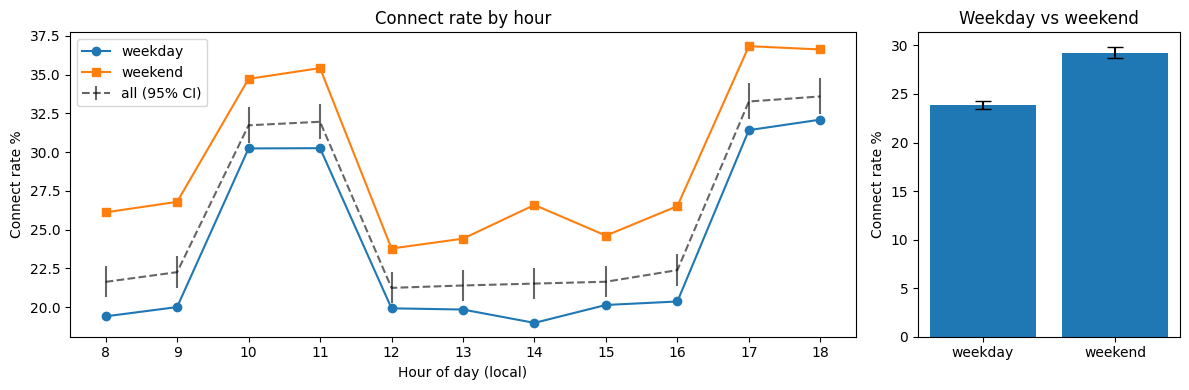

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [3, 1]})
for col, m in [('weekday', 'o'), ('weekend', 's')]:
    ax[0].plot(by_hour_we.index, by_hour_we[col] * 100, marker=m, label=col)
ax[0].errorbar(by_hour.index, by_hour.rate * 100, yerr=[(by_hour.rate - by_hour.ci_low) * 100, (by_hour.ci_high - by_hour.rate) * 100],
               fmt='k--', alpha=.6, label='all (95% CI)')
ax[0].set(xlabel='Hour of day (local)', ylabel='Connect rate %', title='Connect rate by hour', xticks=range(8, 19)); ax[0].legend()
ax[1].bar(by_we.index, by_we.rate * 100, yerr=[(by_we.rate - by_we.ci_low) * 100, (by_we.ci_high - by_we.rate) * 100], capsize=6)
ax[1].set(ylabel='Connect rate %', title='Weekday vs weekend')
plt.tight_layout(); plt.savefig('connect_rate.png', dpi=110); plt.show()

In [4]:
peak = df.hour.isin([10, 11, 17, 18])
peak_rate, off_rate = df[peak].connected.mean(), df[~peak].connected.mean()
print(f'peak hours 10-12 & 17-19: {peak_rate:.1%} ({peak.sum()} calls) | other hours: {off_rate:.1%} ({(~peak).sum()} calls)')
print(f'relative lift of peak hours: {peak_rate / off_rate - 1:.0%}')

peak hours 10-12 & 17-19: 32.6% (25306 calls) | other hours: 21.7% (44929 calls)
relative lift of peak hours: 50%


**Finding.** Connect rate has two clear peaks, **10:00–12:00 and 17:00–19:00 (~32–34%)**, against a flat ~21–22% in every other hour. Weekends connect at **29.3% vs 23.8%** on weekdays, and the weekend lift holds in every hour, so the two effects add up. Both are highly significant (see the chi-square / z output). Calls are spread evenly across hours today, so the dialer is not exploiting this.

## 2. PTP rate by DPD band, and PTP kept rate by days-to-promise

In [5]:
rpc = df[df.rpc]
ptp_dpd = rate_table(rpc, 'dpd_band', 'ptp')
display(ptp_dpd[['n','k','rate','ci_low','ci_high']])
slope, intercept, r, p, se = stats.linregress(rpc.dpd, rpc.ptp.astype(float))
print(f'linear fit: PTP rate falls {-slope*30:.1%} per 30 DPD (p={p:.1e})')

,n,k,rate,ci_low,ci_high
dpd_band,,,,,
1-30,4094,1151,0.2811,0.2676,0.2951
31-60,4119,1055,0.2561,0.2430,0.2697
61-90,4199,900,0.2143,0.2022,0.2270
91-120,4104,786,0.1915,0.1798,0.2038


linear fit: PTP rate falls 3.1% per 30 DPD (p=6.5e-27)


In [6]:
ptp = df[df.ptp].copy()
ptp['kept'] = ptp.ptp_kept.astype(bool)
kept_days = rate_table(ptp, 'days_to_promise', 'kept')
display(kept_days[['n','k','rate','ci_low','ci_high']])
ptp['window'] = np.where(ptp.days_to_promise <= 5, '1-5 days', '6-14 days')
kept_win = rate_table(ptp, 'window', 'kept'); display(kept_win[['n','k','rate','ci_low','ci_high']])
z, p = two_proportion_z(kept_win.k.iloc[0], kept_win.n.iloc[0], kept_win.k.iloc[1], kept_win.n.iloc[1])
print(f'1-5 vs 6-14 days: z={z:.1f}, p={p:.1e}')

,n,k,rate,ci_low,ci_high
days_to_promise,,,,,
1.0000,259,162,0.6255,0.5651,0.6822
2.0000,280,194,0.6929,0.6365,0.7440
3.0000,287,181,0.6307,0.5734,0.6844
4.0000,306,188,0.6144,0.5587,0.6672
5.0000,267,183,0.6854,0.6274,0.7381
6.0000,266,84,0.3158,0.2629,0.3739
7.0000,263,90,0.3422,0.2875,0.4014
8.0000,257,88,0.3424,0.2871,0.4024
9.0000,300,103,0.3433,0.2919,0.3987


,n,k,rate,ci_low,ci_high
window,,,,,
1-5 days,1399,908,0.6490,0.6236,0.6736
6-14 days,2493,858,0.3442,0.3258,0.3630


1-5 vs 6-14 days: z=18.3, p=4.6e-75


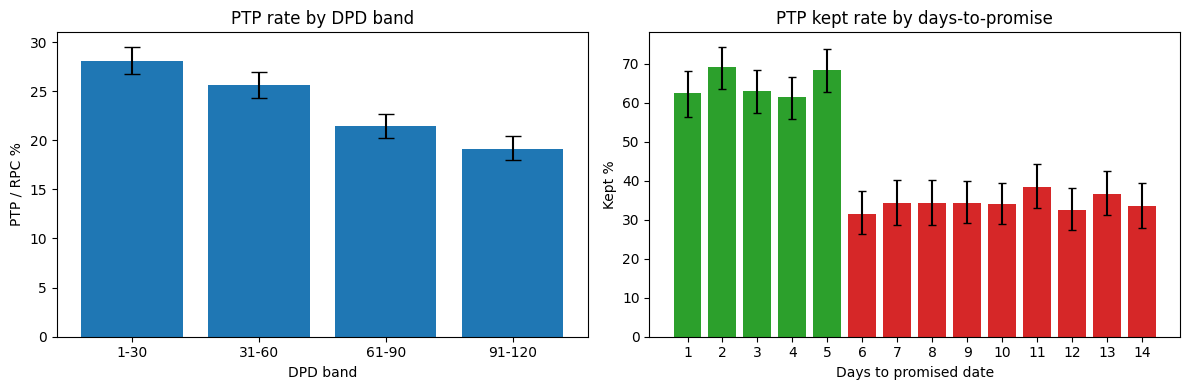

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(ptp_dpd.index.astype(str), ptp_dpd.rate * 100, yerr=[(ptp_dpd.rate-ptp_dpd.ci_low)*100, (ptp_dpd.ci_high-ptp_dpd.rate)*100], capsize=6)
ax[0].set(xlabel='DPD band', ylabel='PTP / RPC %', title='PTP rate by DPD band')
ax[1].bar(kept_days.index.astype(int), kept_days.rate * 100, yerr=[(kept_days.rate-kept_days.ci_low)*100, (kept_days.ci_high-kept_days.rate)*100], capsize=3,
          color=['tab:green' if d <= 5 else 'tab:red' for d in kept_days.index])
ax[1].set(xlabel='Days to promised date', ylabel='Kept %', title='PTP kept rate by days-to-promise', xticks=range(1, 15))
plt.tight_layout(); plt.savefig('ptp_rates.png', dpi=110); plt.show()

**Finding.** PTP rate falls steadily with delinquency, from **28.1% at 1–30 DPD to 19.2% at 91–120** (about 3 pp per 30 days). Kept rate is a **step function, not a slope**: about **65% for promises 1–5 days out against about 34% for 6–14 days**, flat within each side. The cliff is between day 5 and day 6. Caveat: in real data, the borrowers who pick short dates may differ from those who pick long ones (selection), so the causal effect of *asking* for a short date should be confirmed with an A/B test.

## 3. Anomalous segment
I scan every state, batch and state×batch cell for connect rate, wrong-number rate (among connected) and PTP rate (among RPC), each cell against the rest, with Bonferroni correction for the number of cells tested.

In [8]:
conn = df[df.connected]
results = {}
for name, frame, flag in [('connect', df, 'connected'), ('wrong_number|connected', conn, 'wrong'), ('ptp|rpc', rpc, 'ptp')]:
    for cols in (['state'], ['batch'], ['state', 'batch']):
        r = segment_scan(frame, cols, flag)
        sig = r[r.p_bonferroni < 0.01]
        results[(name, tuple(cols))] = r
        print(f'{name:24s} by {"x".join(cols):12s}: {len(r):2d} cells, significant after Bonferroni: '
              + (', '.join(f"{'/'.join(str(row[c]) for c in cols)} ({row.rate:.1%} vs {row.rest_rate:.1%})" for _, row in sig.iterrows()) or 'none'))

connect                  by state       :  6 cells, significant after Bonferroni: none
connect                  by batch       :  8 cells, significant after Bonferroni: none
connect                  by statexbatch : 48 cells, significant after Bonferroni: none
wrong_number|connected   by state       :  6 cells, significant after Bonferroni: BR (13.9% vs 7.7%)
wrong_number|connected   by batch       :  8 cells, significant after Bonferroni: B7 (11.0% vs 8.0%)
wrong_number|connected   by statexbatch : 48 cells, significant after Bonferroni: BR/B7 (53.5% vs 7.8%)
ptp|rpc                  by state       :  6 cells, significant after Bonferroni: none
ptp|rpc                  by batch       :  8 cells, significant after Bonferroni: none
ptp|rpc                  by statexbatch : 48 cells, significant after Bonferroni: none


In [9]:
display(results[('wrong_number|connected', ('state', 'batch'))].head(6))
seg = (df.state == 'BR') & (df.batch == 'B7')
c = df[df.connected]
tbl = pd.DataFrame({
    'BR x B7': [c[seg[c.index]].wrong.mean()],
    'BR, other batches': [c[(c.state == 'BR') & (c.batch != 'B7')].wrong.mean()],
    'B7, other states': [c[(c.batch == 'B7') & (c.state != 'BR')].wrong.mean()],
    'everything else': [c[~seg[c.index]].wrong.mean()]}, index=['wrong-number rate among connected'])
display(tbl)

,state,batch,n,k,rate,rest_rate,z,p,p_bonferroni
0,BR,B7,213,114,0.5352,0.0782,23.9612,0.0000,0.0000
1,MH,B8,576,62,0.1076,0.0828,2.1221,0.0338,1.0000
2,KA,B1,323,36,0.1115,0.0831,1.8278,0.0676,1.0000
3,UP,B6,443,46,0.1038,0.0831,1.5612,0.1185,1.0000
4,GJ,B7,296,30,0.1014,0.0833,1.1150,0.2648,1.0000
5,GJ,B2,318,32,0.1006,0.0833,1.1095,0.2672,1.0000


,BR x B7,"BR, other batches","B7, other states",everything else
wrong-number rate among connected,0.5352,0.0855,0.0662,0.0782


In [10]:
acc = pd.read_csv('accounts.csv')
seg_acc = acc[(acc.state == 'BR') & (acc.batch == 'B7')]
s = df[seg]
base_wrong = c[~seg[c.index]].wrong.mean()
seg_conn, seg_wrong = int(s.connected.sum()), int(s.wrong.sum())
excess_wrong = seg_wrong - seg_conn * base_wrong
print(f'accounts: {len(seg_acc)} ({len(seg_acc)/len(acc):.1%} of book), outstanding: Rs {seg_acc.outstanding.sum():,} ')
print(f'calls: {len(s)}, connected: {seg_conn}, wrong numbers: {seg_wrong} ({seg_wrong/seg_conn:.1%}) vs baseline {base_wrong:.1%}')
print(f'excess wrong-number connects/month: {excess_wrong:.0f}')
print(f'segment connect rate {s.connected.mean():.1%} vs book {df.connected.mean():.1%}; PTP|RPC {s[s.rpc].ptp.mean():.1%} vs book {rpc.ptp.mean():.1%}')
acct_wrong = s.groupby('account_id').wrong.any()
print(f'accounts in segment with >=1 wrong-number call this month: {acct_wrong.sum()} of {len(seg_acc)} ({acct_wrong.mean():.0%})')

accounts: 238 (1.2% of book), outstanding: Rs 9,265,486 
calls: 852, connected: 213, wrong numbers: 114 (53.5%) vs baseline 7.8%
excess wrong-number connects/month: 97


segment connect rate 25.0% vs book 25.7%; PTP|RPC 30.3% vs book 23.6%
accounts in segment with >=1 wrong-number call this month: 99 of 238 (42%)


**Finding.** One cell stands out across all three metrics: **Bihar × batch B7**, with a **~54% wrong-number rate among connected calls against ~8% everywhere else** (z ≈ 24, Bonferroni-adjusted p < 1e-6). It is the *intersection* that is bad: Bihar in other batches and B7 in other states are normal (~7–9%), connect rate is normal (25.0% vs 25.7%) and PTP|RPC is not significantly different after correction (30.3% on only ~99 RPCs).So the borrowers are not harder to persuade; we are reaching the wrong people. That points to a contact-data problem in the B7 allocation file for Bihar (e.g. a vendor/skip-trace source or a column shift in the upload), not a behavioural one.

**Operationally:** (1) suppress BR×B7 from the dialer today; each wrong-number call risks disclosing a debt to a third party, which is a compliance issue, not just wasted dials. (2) Ask the lender/data team for the source of B7-Bihar phone numbers and diff against the previous allocation. (3) Re-skip-trace those 238 accounts and re-verify numbers (e.g. a penny-drop or SMS OTP) before re-enabling them. (4) Add a daily monitor: wrong-number rate by state×batch with an alert at more than 3× baseline and n ≥ 50 connects.

## 4. Impact sizing for the memo
All inputs are computed from this month's data. Assumptions are explicit and varied in a sensitivity table.

In [11]:
rpc_per_conn = df.rpc.sum() / df.connected.sum()
ptp_per_rpc = df.ptp.sum() / df.rpc.sum()
kept_per_ptp = ptp.kept.mean()
print(f'funnel: connect {df.connected.mean():.1%} -> RPC|conn {rpc_per_conn:.1%} -> PTP|RPC {ptp_per_rpc:.1%} -> kept|PTP {kept_per_ptp:.1%}')
base = dict(attempts=len(df), connects=int(df.connected.sum()), rpc=int(df.rpc.sum()), ptp=int(df.ptp.sum()), kept=int(ptp.kept.sum()))
print(base)

# R1: move a share of off-peak weekday attempts into peak hours, same number of attempts
rows = []
for share in (0.10, 0.20, 0.30):
    moved = (~peak).sum() * share
    extra_conn = moved * (peak_rate - off_rate)
    extra_kept = extra_conn * rpc_per_conn * ptp_per_rpc * kept_per_ptp
    rows.append({'share_of_offpeak_moved': share, 'attempts_moved': round(moved), 'extra_connects': round(extra_conn),
                 'connect_lift': extra_conn / base['connects'], 'extra_ptp': round(extra_conn * rpc_per_conn * ptp_per_rpc), 'extra_kept': round(extra_kept)})
r1 = pd.DataFrame(rows); display(r1)

funnel: connect 25.7% -> RPC|conn 91.6% -> PTP|RPC 23.6% -> kept|PTP 45.4%
{'attempts': 70235, 'connects': 18022, 'rpc': 16516, 'ptp': 3892, 'kept': 1766}


,share_of_offpeak_moved,attempts_moved,extra_connects,connect_lift,extra_ptp,extra_kept
0,0.1000,4493,490,0.0272,106,48
1,0.2000,8986,980,0.0544,212,96
2,0.3000,13479,1470,0.0816,317,144


In [12]:
# R2: anchor promise dates to <= 5 days. Assumption: a share of borrowers who would have said 6-14 days accept <= 5 days
# and then keep at the short-window rate. Upper bound because of selection (see section 2 caveat).
n_long = int((ptp.days_to_promise > 5).sum())
k_short, k_long = kept_win.rate.iloc[0], kept_win.rate.iloc[1]
r2 = pd.DataFrame([{'accept_share': a, 'ptps_converted': round(n_long * a), 'extra_kept': round(n_long * a * (k_short - k_long)),
                    'kept_lift': n_long * a * (k_short - k_long) / base['kept']} for a in (0.25, 0.50, 0.75)])
print(f'PTPs with 6-14 day dates this month: {n_long} of {len(ptp)} ({n_long/len(ptp):.0%}); kept {k_short:.1%} vs {k_long:.1%}')
display(r2)

# R3: fix BR x B7 contact data -> wrong-number rate back to baseline
extra_rpc = excess_wrong
print(f'R3: +{extra_rpc:.0f} RPCs/month, +{extra_rpc*ptp_per_rpc:.0f} PTPs, +{extra_rpc*ptp_per_rpc*kept_per_ptp:.0f} kept; '
      f'{seg_wrong} third-party contacts/month avoided immediately by suppression; Rs {seg_acc.outstanding.sum()/1e5:.1f} lakh outstanding re-reachable')

PTPs with 6-14 day dates this month: 2493 of 3892 (64%); kept 64.9% vs 34.4%


,accept_share,ptps_converted,extra_kept,kept_lift
0,0.2500,623,190,0.1076
1,0.5000,1246,380,0.2152
2,0.7500,1870,570,0.3228


R3: +97 RPCs/month, +23 PTPs, +10 kept; 114 third-party contacts/month avoided immediately by suppression; Rs 92.7 lakh outstanding re-reachable
